# OpenBCI Cyton+Daisy QC

This notebook **is** the quality check. Command-click BrainFlow `.csv` files in one folder, then **Add more** (another folder), **Replace**, or **Done**. Re-run that cell to add files you missed. Each file is scored with `analysis/openbci_qc.py`.

A file **PASSes** if it has at least **8 USABLE** channels and **5 minutes** of data (45 s settle, 10 s windows, 1–40 Hz + 60 Hz notch). `openbci_patterns.ipynb` **calls the same module** — it does not copy these rules — and only pools files that pass.

Use the **attn_analysis** kernel, not **attn**. `attn` cannot rasterize PNG.


In [1]:
from pathlib import Path
import os, sys
cwd = Path.cwd().resolve()
if (cwd / "analysis").is_dir() and (cwd / "experiments").is_dir():
    REPO_ROOT = cwd
elif cwd.name == "analysis":
    REPO_ROOT = cwd.parent
else:
    REPO_ROOT = cwd
os.chdir(REPO_ROOT)
sys.path.insert(0, str(REPO_ROOT / "analysis"))
print("REPO_ROOT:", REPO_ROOT)
print("kernel:", sys.executable)
%matplotlib inline
if "/envs/attn/" in sys.executable.replace("\\", "/") and "attn_analysis" not in sys.executable:
    print("Switch kernel to attn_analysis, then re-run from the top. Falling back to SVG plots.")
    %config InlineBackend.figure_format = "svg"


REPO_ROOT: /Users/sonipriyapaul/Downloads/AttentionSpan
kernel: /opt/miniconda3/envs/attn/bin/python
Switch kernel to attn_analysis, then re-run from the top. Falling back to SVG plots.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from io import BytesIO
from IPython.display import SVG, display
import openbci_qc as oqc

FS = oqc.FS
N_CH = oqc.N_CH
BP = oqc.BP
NOTCH_HZ = oqc.NOTCH_HZ
SETTLE_SEC = oqc.SETTLE_SEC
WIN_SEC = oqc.WIN_SEC
CHANNEL_LABELS = oqc.CHANNEL_LABELS
MIN_USABLE_CH = oqc.MIN_USABLE_CH
MIN_MINUTES = oqc.MIN_MINUTES
QC_ROOT = oqc.qc_output_root(REPO_ROOT)


def show_fig(fig, name, out_dir):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    path = out_dir / Path(name).with_suffix(".svg").name
    try:
        buf = BytesIO()
        fig.savefig(str(path), format="svg")
        fig.savefig(buf, format="svg")
        plt.close(fig)
        buf.seek(0)
        display(SVG(buf.getvalue()))
        print("saved", path)
    except Exception as e:
        plt.close(fig)
        print(f"skipped figure {name}: {e}")
        print("Switch kernel to attn_analysis (Kernel → Change Kernel) for plots.")


## Select CSVs (Command-click several)

Run the next cell. A list asks **what the next files are**:

- **Baseline (set 1)** — no phone. All baseline CSVs you add (any folder, any day) are **pooled together** into one baseline pattern.
- **Set 2 / 3 / 4** — reply / glance / auditory. Those files are **not** mixed with baseline, and set 2 is not mixed with set 3.

Finder then opens (Command-click in one folder). **Add more** if the rest of that group is in another folder. When that group is done, the list comes back so you can tag the next group. Re-run the cell to add or replace.


In [3]:
ELECTRODES = "Cyton+Daisy dry"
PLOT_EACH = True          # 16-ch excerpt / PSD / band stack per file (set False for gate-only)

FILES = oqc.pick_labeled_sessions(
    existing=globals().get("FILES") or [],
    electrodes=ELECTRODES,
)
if not FILES:
    raise RuntimeError("No files tagged. Re-run this cell and choose Baseline or Set 2/3/4.")

print("\nPooling groups (baseline together; each distract set on its own):")
for s in FILES:
    print(f"  {s['condition']:12} set={s['set']}  {s['task']:22}  {s['path'].name}")
n_base = sum(s["condition"] == "baseline" for s in FILES)
print(f"{n_base} baseline file(s), {len(FILES) - n_base} distract file(s)")


No files tagged yet.
Set 4 - auditory, eyes on screen: 1 file(s)
  OpenBCISession_2026-11-05_16-27-22_soni_set4/BrainFlow-RAW_2026-11-05_16-27-22_soni_set4_0.csv
Tagged files (this is how they will be pooled):
  distracted   set=4  BrainFlow-RAW_2026-11-05_16-27-22_soni_set4_0.csv

Pooling groups (baseline together; each distract set on its own):
  distracted   set=4  set 4 auditory          BrainFlow-RAW_2026-11-05_16-27-22_soni_set4_0.csv
0 baseline file(s), 1 distract file(s)


## QC each file

Same rules for every CSV: drop packet-loss rows, split on gaps **> 0.25 s**, skip **45 s** settle, median offset, 60 Hz notch, **1–40 Hz** band-pass, score **10 s** windows.

- **USABLE**: ≥80% of windows clean, spectrum still falls with frequency
- **MARGINAL**: ≥50% clean
- **ARTIFACT**: too few clean windows
- **RAILED / dead**: ≥5% at the ADC rail, or near-zero RMS


In [4]:
missing = [s["id"] for s in FILES if not Path(s["path"]).exists()]
if missing:
    raise FileNotFoundError("Missing: " + ", ".join(missing))

records = []
for spec in FILES:
    print(f"\n=== {spec['id']}  ({spec['condition']})  set={spec['set']}")
    rec = oqc.qc_file(spec["path"], verbose=True)
    rec.update(spec)
    rec["out_dir"] = QC_ROOT / spec["path"].stem.replace(" ", "_")
    rec["out_dir"].mkdir(parents=True, exist_ok=True)
    rec["qc"].to_csv(rec["out_dir"] / "channel_qc_table.csv", index=False)
    if len(rec["win"]):
        rec["win"].to_csv(rec["out_dir"] / "window_qc_table.csv", index=False)
    print(rec["qc"][["ch", "label", "verdict", "% windows clean", "median win RMS µV", "dominant band"]].round(1).to_string(index=False))
    print("USABLE:", rec["qc"].loc[rec["qc"].verdict == "USABLE", "ch"].tolist())
    records.append(rec)
print(f"\nQC'd {len(records)} file(s)")



=== 2026-11-05_16-27-22_soni_set4_0  (distracted)  set=4
QC  BrainFlow-RAW_2026-11-05_16-27-22_soni_set4_0.csv
  369,007 samples  125 Hz  49.2 min
  3 segment(s) after 45s settle; 348,216 samples (46.4 min); filter 1–40 Hz + 60 Hz notch
 ch label       verdict  % windows clean  median win RMS µV dominant band
  0   Fp1 RAILED / dead             32.0               53.0         delta
  1   Fp2 RAILED / dead              0.0                0.0             -
  2    C3        USABLE            100.0                9.5         delta
  3    C4        USABLE            100.0               11.8         delta
  4    P7        USABLE             98.9                8.5         delta
  5    P8        USABLE            100.0               10.2         delta
  6    O1        USABLE             83.8               17.0         delta
  7    O2        USABLE             95.7               10.2         delta
  8    F7        USABLE             94.6               13.8         delta
  9    F8        USABL

## Gate — only PASS files are written for patterns

A file passes if it has at least `MIN_USABLE_CH` USABLE channels and `MIN_MINUTES` of recording. Failed files stay in the tables below so you can see why, but `last_run.json` marks them `FAIL` and patterns will drop them.


Gate: ≥8 USABLE channels and ≥5 min.

--- 2026-11-05_16-27-22_soni_set4_0  distracted  set=4  PASS
 ch label       verdict  pct_windows_clean  median_rms_uV dominant
  0   Fp1 RAILED / dead          32.014388      53.040799    delta
  1   Fp2 RAILED / dead           0.000000       0.000000        -
  2    C3        USABLE         100.000000       9.452033    delta
  3    C4        USABLE         100.000000      11.757094    delta
  4    P7        USABLE          98.920863       8.491717    delta
  5    P8        USABLE         100.000000      10.240655    delta
  6    O1        USABLE          83.812950      16.964106    delta
  7    O2        USABLE          95.683453      10.217920    delta
  8    F7        USABLE          94.604317      13.785419    delta
  9    F8        USABLE          95.683453      19.117787    delta
 10    F3        USABLE         100.000000      13.724848    delta
 11    F4        USABLE         100.000000      15.489334    delta
 12    T7        USABLE       

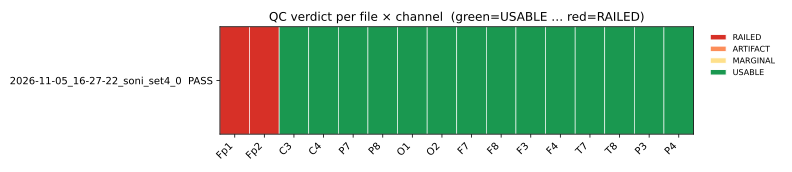

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/openbci_qc/qc_gate_heatmap.svg
wrote /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/openbci_qc/last_run.json
Patterns notebook: set USE_LAST_QC_RUN = True and it will call this QC on these files.
1 / 1 file(s) PASS


In [5]:
GATE = oqc.summarize_gate(records, verbose=True)
print(GATE.to_string(index=False))
GATE.to_csv(QC_ROOT / "qc_gate.csv", index=False)

heat = oqc.gate_heatmap_array(records)
fig, ax = plt.subplots(figsize=(11, max(2.4, 0.5 * len(records) + 1.4)))
oqc.draw_gate_heatmap(
    ax, heat,
    row_labels=[f"{r['id']}  {r['gate_row']['gate']}" for r in records],
    col_labels=[CHANNEL_LABELS[c] for c in range(N_CH)],
)
ax.set_title("QC verdict per file × channel  (green=USABLE … red=RAILED)")
fig.tight_layout()
show_fig(fig, "qc_gate_heatmap", QC_ROOT)

run_path = oqc.save_last_run(records, GATE, REPO_ROOT)
print("wrote", run_path)
print("Patterns notebook: set USE_LAST_QC_RUN = True and it will call this QC on these files.")
n_pass = int((GATE.gate == "PASS").sum())
print(f"{n_pass} / {len(GATE)} file(s) PASS")
if n_pass == 0:
    print("Nothing passed. Fix electrodes or lower MIN_USABLE_CH in openbci_qc.py.")


## Time series and spectra (one block per PASS or FAIL file)

Grey bands are **10 s windows the QC rejected**. PSD is the average of **clean** windows only (red dotted if a channel has none). Skip this cell if you only needed the gate (`PLOT_EACH = False`).



plots  2026-11-05_16-27-22_soni_set4_0  PASS


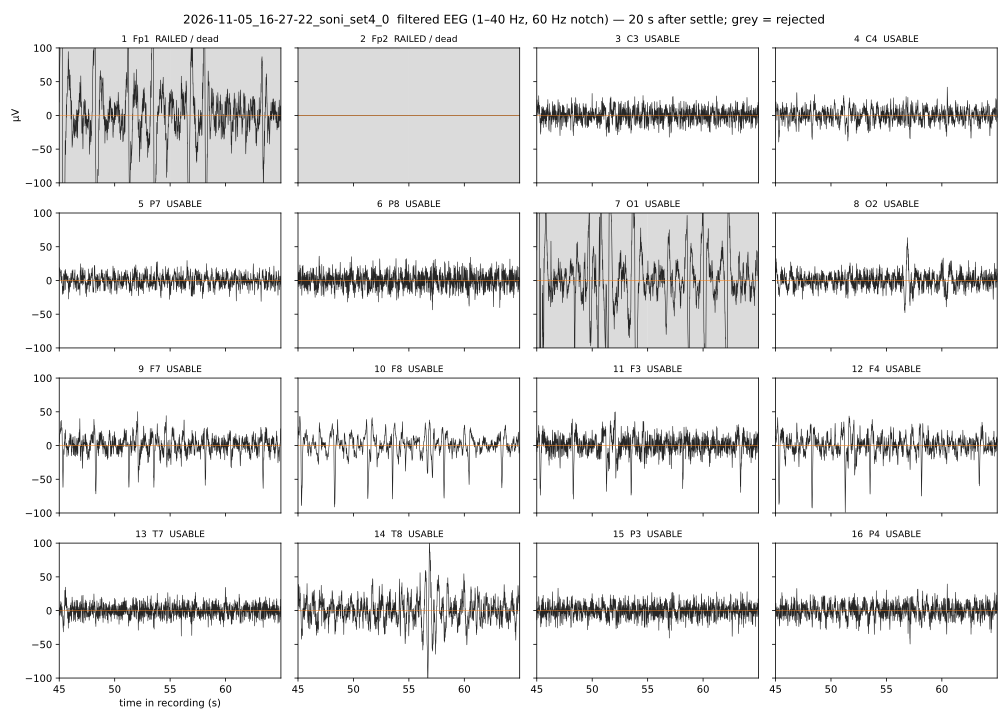

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/openbci_qc/BrainFlow-RAW_2026-11-05_16-27-22_soni_set4_0/filtered_excerpt.svg


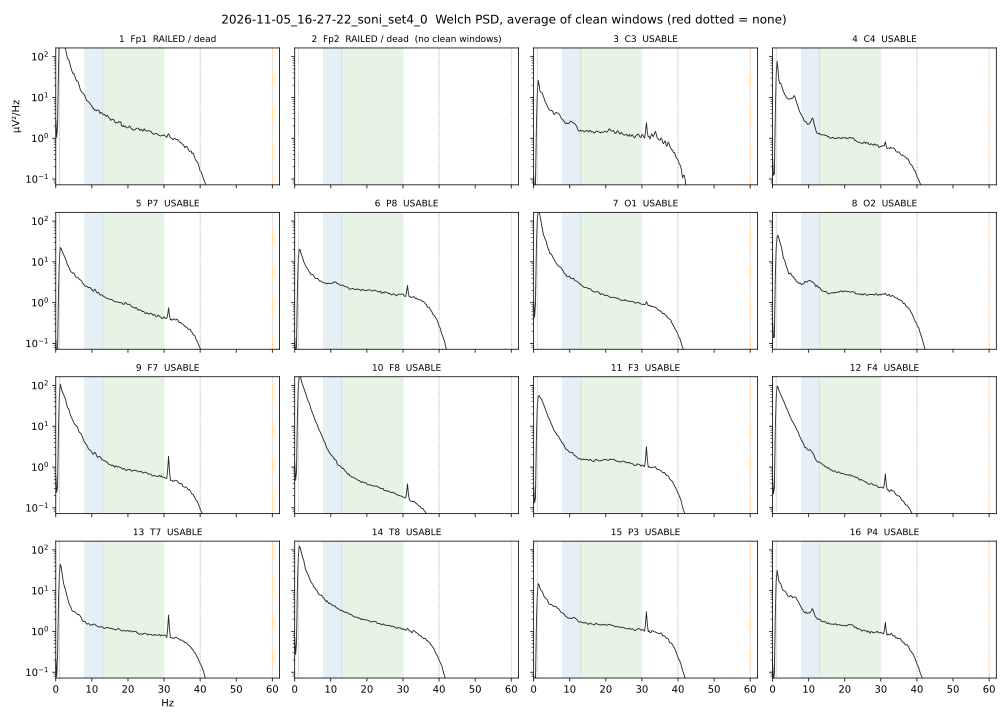

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/openbci_qc/BrainFlow-RAW_2026-11-05_16-27-22_soni_set4_0/psd.svg


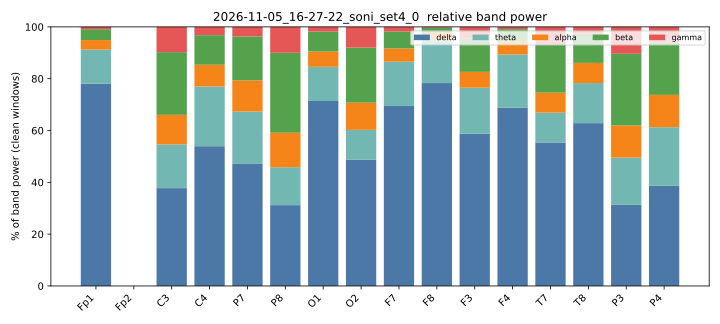

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/openbci_qc/BrainFlow-RAW_2026-11-05_16-27-22_soni_set4_0/band_stack.svg


In [ ]:
def ch_title(qc, c):
    
    return f"{c + 1}  {CHANNEL_LABELS[c]}  {qc.loc[c, 'verdict']}"


def plot_excerpt(rec):
    segs, win, qc, fs = rec["segs"], rec["win"], rec["qc"], rec["fs"]
    if not segs:
        print(rec["id"], "no segment long enough after settle")
        return
    seg0 = segs[0]
    eeg_f = seg0["filt"]
    n_ex = min(len(eeg_f), int(20 * fs))
    tt = SETTLE_SEC + np.arange(n_ex) / fs
    w0 = win[win.seg == seg0["id"]] if len(win) else win
    fig, axes = plt.subplots(4, 4, figsize=(14, 10), sharex=True, sharey=True)
    for c, ax in enumerate(axes.ravel()):
        if n_ex:
            ax.plot(tt, eeg_f[:n_ex, c], lw=0.6, color="0.15")
        if len(w0):
            for _, r in w0[(w0.ch == c) & (~w0.clean)].iterrows():
                ax.axvspan(r.t_start_s, r.t_start_s + WIN_SEC, color="0.6", alpha=0.35, lw=0)
        ax.axhline(0, color="C1", lw=0.5)
        ax.set_title(ch_title(qc, c), fontsize=9)
        if n_ex:
            ax.set_xlim(tt[0], tt[-1])
        ax.set_ylim(-100, 100)
    axes[3, 0].set_xlabel("time in recording (s)")
    axes[0, 0].set_ylabel("µV")
    fig.suptitle(
        f"{rec['id']}  filtered EEG ({BP[0]:g}–{BP[1]:g} Hz, {NOTCH_HZ:.0f} Hz notch) — 20 s after settle; grey = rejected"
    )
    fig.tight_layout()
    show_fig(fig, "filtered_excerpt.svg", rec["out_dir"])


def plot_psd(rec):
    segs, win, qc, fs = rec["segs"], rec["win"], rec["qc"], rec["fs"]
    curves = []
    for c in range(N_CH):
        clean = oqc.clean_signal(segs, win, c, fs)
        used = len(clean) > 0
        wlen = int(WIN_SEC * fs)
        pieces = clean if used else [
            s["filt"][k * wlen:(k + 1) * wlen, c]
            for s in segs for k in range(len(s["filt"]) // wlen)
        ]
        if not pieces:
            curves.append((None, None, False))
            continue
        ps = []
        for p in pieces:
            f, pxx = oqc._psd(p, fs)
            ps.append(pxx)
        curves.append((f, np.mean(ps, axis=0), used))
    lo_f, hi_f = max(2.0, BP[0] * 1.2), BP[1] - 3
    shown = [p[(f >= lo_f) & (f <= hi_f)] for f, p, ok in curves if f is not None and ok]
    if shown:
        cat = np.concatenate(shown)
        ylo, yhi = np.percentile(cat, 1) / 2, np.percentile(cat, 99.5) * 2
    else:
        ylo, yhi = None, None
    fig, axes = plt.subplots(4, 4, figsize=(14, 10), sharex=True, sharey=True)
    for c, ax in enumerate(axes.ravel()):
        f, p, ok = curves[c]
        if f is not None:
            ax.semilogy(f, p, lw=0.9, color="0.15" if ok else "C3", ls="-" if ok else ":")
        for (lo, hi), col in [((8, 13), "C0"), ((13, 30), "C2")]:
            ax.axvspan(lo, hi, color=col, alpha=0.12)
        for x in (BP[0], BP[1]):
            ax.axvline(x, color="0.5", ls=":", lw=0.8)
        ax.axvline(NOTCH_HZ, color="C1", ls=":", lw=0.8)
        ax.set_xlim(0, 62)
        if ylo is not None:
            ax.set_ylim(ylo, yhi)
        extra = "" if (f is not None and ok) else "  (no clean windows)"
        ax.set_title(ch_title(qc, c) + extra, fontsize=9)
    axes[3, 0].set_xlabel("Hz")
    axes[0, 0].set_ylabel("µV²/Hz")
    fig.suptitle(f"{rec['id']}  Welch PSD, average of clean windows (red dotted = none)")
    fig.tight_layout()
    show_fig(fig, "psd.svg", rec["out_dir"])


def plot_bands(rec):
    qc = rec["qc"]
    fig, ax = plt.subplots(figsize=(10, 4.5))
    rel_cols = ["% delta", "% theta", "% alpha", "% beta", "% gamma"]
    bottom = np.zeros(N_CH)
    colors = ["#4C78A8", "#72B7B2", "#F58518", "#54A24B", "#E45756"]
    for col, c in zip(rel_cols, colors):
        vals = qc[col].fillna(0).to_numpy() if col in qc.columns else np.zeros(N_CH)
        ax.bar(qc["ch"], vals, bottom=bottom, color=c, label=col.replace("% ", ""), width=0.8)
        bottom += vals
    ax.set_xticks(range(N_CH))
    ax.set_xticklabels([CHANNEL_LABELS[c] for c in range(N_CH)], rotation=45, ha="right")
    ax.set_ylabel("% of band power (clean windows)")
    ax.set_title(f"{rec['id']}  relative band power")
    ax.legend(ncols=5, fontsize=8, loc="upper right")
    ax.set_ylim(0, 100)
    fig.tight_layout()
    show_fig(fig, "band_stack.svg", rec["out_dir"])


if not PLOT_EACH:
    print("PLOT_EACH is False — skip plots. Gate and last_run.json are enough for patterns.")
else:
    for rec in records:
        print(f"\nplots  {rec['id']}  {rec['gate_row']['gate']}")
        plot_excerpt(rec)
        plot_psd(rec)
        plot_bands(rec)
